**PM2.5 Multiple Linear Regression**

In this notebook, we will load the cleaned dataset, separate the inputs and target, split the data, train a multiple linear regression model, evaluate it, visualize its predictions, and save it for the Flask application

In [1]:
from pathlib import Path
import os

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

***1. Load the cleaned dataset***

The path code works whether Jupyter starts in the project root or inside the notebooks folder.

In [2]:
CURRENT_FOLDER = Path.cwd()
PROJECT_ROOT = CURRENT_FOLDER.parent if CURRENT_FOLDER.name == "notebooks" else CURRENT_FOLDER

DATA_FILE = PROJECT_ROOT / "dataset" / "air_quality_merged_clean.csv"
MODELS_DIR = PROJECT_ROOT / "models"
MODEL_FILE = MODELS_DIR / "pm25_linear_regression.joblib"

data = pd.read_csv(DATA_FILE)

print("Dataset shape:", data.shape)
display(data.head())

Dataset shape: (338032, 8)


,pm10,no2,so2,co,ozone,humidity,wind_speed,pm25
0,59.48,3.80,9.03,4.90,13.61,68.53,1.53,12.38
1,497.25,13.18,4.78,5.53,0.55,81.75,0.75,359.00
2,139.43,4.93,7.52,0.27,78.84,41.30,0.72,32.90
3,224.83,19.79,14.68,0.51,32.52,70.78,0.59,96.75
4,16.75,12.88,3.48,0.73,6.07,78.50,1.20,3.00


***2. Separate inputs and target, then split the data***

X contains the seven measurements used as inputs. y contains PM2.5, the value we want the model to learn. We use 80% of the rows for training and keep 20% for testing.

In [3]:
FEATURES = [
    "pm10",
    "no2",
    "so2",
    "co",
    "ozone",
    "humidity",
    "wind_speed",
]
TARGET = "pm25"

X = data[FEATURES]
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 270425
Testing rows: 67607


**3. Standardize the inputs and train the model**

The pipeline first standardizes the input features and then trains linear regression. Keeping both operations together ensures that future Flask inputs receive exactly the same scaling as the training data.

In [4]:
model_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression()),
    ]
)

model_pipeline.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


**4. Predict and evaluate**

MAE is the average absolute prediction error. RMSE gives extra importance to large errors. R2 shows how much of the variation in PM2.5 is explained by the model.

In [5]:
predictions = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"MAE:  {mae:.3f} ug/m3")
print(f"RMSE: {rmse:.3f} ug/m3")
print(f"R2:   {r2:.4f}")

results = pd.DataFrame({
    "actual_pm25": y_test.to_numpy(),
    "predicted_pm25": predictions,
})
display(results.head(10))

MAE:  19.025 ug/m3
RMSE: 31.309 ug/m3
R2:   0.7280


,actual_pm25,predicted_pm25
0,61.68,53.744778
1,73.37,75.214706
2,266.00,236.048457
3,26.75,32.985111
4,75.77,41.308691
5,51.20,50.544919
6,60.03,113.213916
7,7.00,11.393458
8,63.00,106.161200
9,19.05,13.089257


**5. Plot actual values against predictions**

The dashed red line represents perfect predictions. Points closer to this line are predicted more accurately

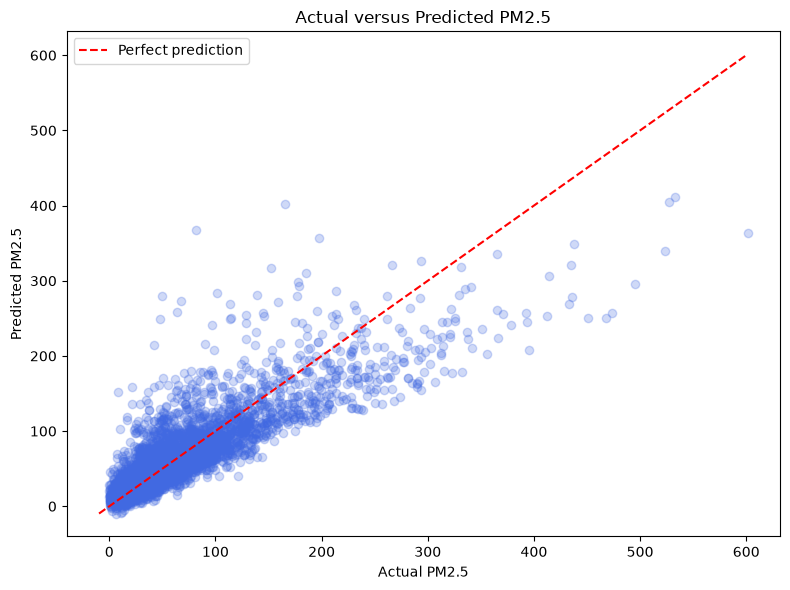

In [6]:
plot_results = results.sample(
    n=min(5_000, len(results)),
    random_state=42,
)

minimum_value = min(
    plot_results["actual_pm25"].min(),
    plot_results["predicted_pm25"].min(),
)
maximum_value = max(
    plot_results["actual_pm25"].max(),
    plot_results["predicted_pm25"].max(),
)

plt.figure(figsize=(8, 6))
plt.scatter(
    plot_results["actual_pm25"],
    plot_results["predicted_pm25"],
    alpha=0.25,
    color="royalblue",
)
plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    color="red",
    linestyle="--",
    label="Perfect prediction",
)
plt.title("Actual versus Predicted PM2.5")
plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.legend()
plt.tight_layout()
plt.show()

**7. Save the complete pipeline**

Saving the pipeline keeps the trained scaler and regression model together. The Flask application can therefore apply the same preprocessing before every prediction.

In [7]:
os.makedirs(MODELS_DIR, exist_ok=True)

model_artifact = {
    "pipeline": model_pipeline,
    "features": FEATURES,
    "target": TARGET,
    "metrics": {
        "mae": float(mae),
        "rmse": float(rmse),
        "r2": float(r2),
    },
}

joblib.dump(model_artifact, MODEL_FILE)

print("Model saved successfully.")
print("Location:", MODEL_FILE)

Model saved successfully.
Location: c:\Users\harsh bhuvad\OneDrive\Desktop\ML_Project\Mulitiple_Linear_Regression\models\pm25_linear_regression.joblib
